# Clase 11 — Agentes aplicados: enseñar y difundir

**RL a ciegas** · MOOC libre de aprendizaje por refuerzo · vía profunda

> Un agente de marketing y un agente tutor resuelven el mismo problema: **sostener la atención de alguien**. La diferencia es **a favor de quién juega la recompensa**, y quién puede verla y cambiarla.

Esta clase muestra cómo se produce y se difunde el propio MOOC con agentes: el curso enseña el sistema que lo produce.

1. **Dos agentes, un problema**: el agente de difusión y el tutor como dos MDP con la misma forma.
2. **La fábrica de contenido**: un pipeline multiagente con **modelos de lenguaje reales y chicos** que lee la bibliografía del curso y propone posts.
3. **El tutor como agente**: elige la próxima pregunta; recompensa = acierto vs. recompensa = mejora.
4. **Persuasión a favor del usuario**: una pausa antes del feed cambia el entorno, no el agente.

> **Tiempo y recursos.** Este es el único notebook del curso que descarga modelos (≈ 4 GB en total). En Colab con GPU T4 (gratis) corre en 2–3 minutos; en CPU, entre 5 y 10. Las respuestas de modelos tan chicos son flojas: **eso es parte de la lección** (por eso existen el evaluador y el humano en el bucle).

## Preparación

### ¿Hay GPU?

Los modelos de lenguaje corren mucho más rápido en una GPU. En Colab: menú **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4**, y volver a ejecutar desde acá.

In [1]:
import importlib, subprocess, sys
for paquete in ["transformers", "accelerate"]:          # en Colab ya vienen; por las dudas
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

import torch
if torch.cuda.is_available():
    DEVICE = "cuda"
    print(f"✓ GPU disponible: {torch.cuda.get_device_name(0)}. Los modelos van a correr rápido.")
else:
    DEVICE = "cpu"
    print("⚠ No hay GPU: el notebook corre igual, pero más lento (5–10 min).\n"
          "  En Colab conviene: Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4.")

⚠ No hay GPU: el notebook corre igual, pero más lento (5–10 min).
  En Colab conviene: Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4.


### Los modelos

- **Generador** (curador + redactor): `Qwen/Qwen2.5-0.5B-Instruct`, un modelo abierto de 500 millones de parámetros. Se descarga sin cuenta ni token.
- **Evaluador**: `Qwen/Qwen2.5-1.5B-Instruct`, **otro tamaño de la misma familia** (1500 millones). Generar y evaluar con el mismo modelo mide autocomplacencia, no calidad. ¿Por qué no un modelo chico de otra familia? Probamos evaluadores de menos de 1000 millones de parámetros (SmolLM2-360M, Qwen2.5-0.5B, Qwen3-0.6B) y **no distinguían** un post correcto de uno malo a propósito; lo van a poder comprobar en el ejercicio del Paso 4. Compartir familia tiene un costo: los dos modelos se entrenaron con datos y recetas parecidas, y pueden compartir sesgos. Por eso la tesis de referencia del pipeline (Villanueva, 2026, en la sección 2) usa modelos de **proveedores distintos** para generar y evaluar; acá elegimos lo que corre gratis en Colab.

In [2]:
MODELO_GENERADOR = "Qwen/Qwen2.5-0.5B-Instruct"
MODELO_EVALUADOR = "Qwen/Qwen2.5-1.5B-Instruct"      # otro tamaño de la misma familia: tiene que ser distinto del generador

import os, re, json, time, textwrap, warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

SEMILLA = 0
np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
T0 = time.time()

**Herramientas** (celda plegada): cargar modelos, los tres agentes del pipeline, el alumno simulado, el feed de la clase 9 y las funciones de dibujo. No hace falta leerla, solo ejecutarla.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import gc
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.colors import ListedColormap
from transformers import pipeline
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5, "lines.linewidth": 2,
})


def corto(txt, n=110):
    txt = " ".join(str(txt).split())
    return txt if len(txt) <= n else txt[: n - 1] + "…"


# ================= modelos =================
def _ram_gb():
    try:
        import psutil
        return psutil.virtual_memory().total / 1e9
    except Exception:
        return 8.0


def cargar_generador(nombre):
    dtype = torch.float16 if DEVICE == "cuda" else torch.float32
    t = time.time()
    p = pipeline("text-generation", model=nombre, dtype=dtype, device=DEVICE)
    print(f"✓ Generador: {nombre}  (cargado en {time.time() - t:.0f} s)")
    return p, nombre


def cargar_evaluador(nombre, generador_usado):
    if nombre == generador_usado:
        raise ValueError("El evaluador tiene que ser un modelo distinto del generador.")
    if DEVICE == "cuda":
        dtype = torch.float16
    else:   # en CPU: float32 si hay memoria (Colab tiene ~12 GB); si no, bfloat16 (más lento, la mitad de memoria)
        dtype = torch.float32 if _ram_gb() >= 11 else torch.bfloat16
    t = time.time()
    p = pipeline("text-generation", model=nombre, dtype=dtype, device=DEVICE)
    print(f"✓ Evaluador: {nombre}  ({str(dtype).replace('torch.', '')}, cargado en {time.time() - t:.0f} s)")
    return p


def liberar(*objs):
    for o in objs:
        del o
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


def chat(pipe, texto, max_new_tokens, muestrear=False, semilla=0):
    """Un turno de chat (texto) o una conversación (lista de mensajes). Sin rol 'system': algunas plantillas no lo aceptan."""
    kw = dict(max_new_tokens=max_new_tokens, do_sample=muestrear)
    if muestrear:
        torch.manual_seed(semilla); kw.update(temperature=0.7, top_p=0.9)
    else:
        kw.update(temperature=None, top_p=None, top_k=None)
    msgs = [{"role": "user", "content": texto}] if isinstance(texto, str) else texto
    out = pipe(msgs, **kw)
    return out[0]["generated_text"][-1]["content"].strip()


# ================= parser tolerante =================
def parsear_json(txt):
    """Intenta sacar un dict de una respuesta 'casi JSON'. Devuelve (dict o None, cómo lo logró)."""
    txt = txt.replace("```json", "```").strip()
    m = re.search(r"\{.*\}", txt, re.S)
    cand = m.group(0) if m else txt
    for intento, f in [("JSON válido", lambda s: s),
                       ("JSON reparado", lambda s: re.sub(r",\s*([\]}])", r"\1", s.replace("“", '"').replace("”", '"'))),
                       ("JSON reparado (comillas simples)", lambda s: re.sub(r",\s*([\]}])", r"\1", s.replace("'", '"')))]:
        try:
            d = json.loads(f(cand))
            if isinstance(d, dict):
                return d, intento
        except Exception:
            pass
    # último recurso: una lista de strings entre comillas después de "ideas"
    m = re.search(r"ideas\W*\[(.*?)(\]|$)", txt, re.S | re.I)
    if m:
        items = re.findall(r'"([^"]{10,})"', m.group(1))
        if items:
            return {"ideas": items}, "rescatado con expresiones regulares"
    items = [re.sub(r"^\s*(?:[-*•]|\d+[.)])\s*", "", l).strip() for l in txt.splitlines()
             if re.match(r"^\s*(?:[-*•]|\d+[.)])\s+\S", l)]
    if items:
        return {"ideas": items}, "rescatado de una lista con viñetas"
    return None, "no se pudo leer"


def solape(idea, texto):
    """Fracción de las palabras largas de la idea que aparecen en el fragmento (comparando las 5 primeras letras)."""
    pal = lambda x: [w[:5] for w in re.findall(r"\w+", x.lower()) if len(w) >= 5]
    a, b = pal(idea), set(pal(texto))
    return sum(w in b for w in a) / max(len(a), 1)


def ideas_validas(d, texto, minimo=0.4):
    """Valida: strings de largo razonable y apoyados en el fragmento (si no, el modelo está inventando)."""
    if not d or not isinstance(d.get("ideas"), list):
        return [], 0
    cand = [i.strip() for i in d["ideas"] if isinstance(i, str) and 15 <= len(i.strip()) <= 400]
    ok = [corto(i, 220) for i in cand if solape(i, texto) >= minimo]
    return ok[:3], len(cand) - len(ok)


# ================= agentes del pipeline =================
PROMPT_CURADOR = (
    "Este es un fragmento de un curso de aprendizaje por refuerzo.\n\nFRAGMENTO:\n{texto}\n\n"
    "Escribí las 2 afirmaciones centrales del fragmento, cada una en una oración corta en castellano. "
    "Solo lo que el fragmento afirma: no des consejos de estudio.\n"
    'Respondé SOLO con JSON: {{"ideas": ["primera afirmación", "segunda afirmación"]}}')
PROMPT_CURADOR_ESTRICTO = (
    "Tu respuesta anterior no era JSON válido. Leé el fragmento y respondé ÚNICAMENTE con un objeto JSON, "
    'sin texto antes ni después: {{"ideas": ["...", "..."]}}\n\nFRAGMENTO:\n{texto}')

INSTRUCCION_GENERADOR = (
    "Escribí material educativo breve en castellano para un curso de aprendizaje por refuerzo, con cuatro secciones: "
    "POST (2 o 3 oraciones fieles a la fuente), PREGUNTA (de práctica), RESPUESTA (corta) y FICHA (concepto: definición).\n\n"
    "FUENTE:\n{texto}\n\nIDEA A ENSEÑAR: {idea}")
# Un ejemplo resuelto (few-shot) sobre OTRO tema, como turno previo de la conversación: los modelos chicos copian la forma.
EJEMPLO_GENERADOR = [
    {"role": "user", "content": INSTRUCCION_GENERADOR.format(
        texto="El factor de descuento γ, entre 0 y 1, pesa las recompensas futuras. Con γ = 0 el agente solo mira la "
              "recompensa inmediata; con γ cerca de 1 tiene en cuenta el largo plazo.",
        idea="γ decide cuánto importa el futuro.")},
    {"role": "assistant", "content":
        "POST: El factor de descuento γ decide cuánto le importa el futuro al agente. Con γ = 0 solo mira la recompensa "
        "de ahora; con γ cerca de 1 planea a largo plazo.\nPREGUNTA: Si γ = 0, ¿qué recompensas tiene en cuenta el agente?\n"
        "RESPUESTA: Solo la recompensa inmediata.\nFICHA: Factor de descuento (γ): número entre 0 y 1 que pesa las recompensas futuras."},
]

ETIQUETAS = ["post", "pregunta", "respuesta", "ficha"]


def parsear_secciones(txt):
    patron = r"(?im)^[\s*#>_-]*(post|pregunta|respuesta|ficha)[\s*_]*[:：][\s*_]*"
    partes = re.split(patron, txt)
    sec = {}
    for i in range(1, len(partes) - 1, 2):
        k = partes[i].lower(); v = partes[i + 1].strip().strip("*").strip()
        if k not in sec and v:
            sec[k] = v
    return sec


def curar(estado, gen):
    t = time.time(); estado["intentos_curador"] = []
    for k in range(3):
        prompt = (PROMPT_CURADOR if k == 0 else PROMPT_CURADOR_ESTRICTO).format(texto=estado["fuente"]["texto"])
        crudo = chat(gen, prompt, max_new_tokens=110, muestrear=k > 0, semilla=k)
        d, como = parsear_json(crudo)
        ideas, inventadas = ideas_validas(d, estado["fuente"]["texto"])
        if inventadas:
            como += f"; {inventadas} descartada(s) por no apoyarse en el fragmento"
        estado["intentos_curador"].append({"crudo": crudo, "lectura": como, "ideas_validas": len(ideas)})
        if ideas:
            estado["ideas"] = ideas
            break
    else:
        estado["ideas"] = []
    estado["t_curador"] = time.time() - t
    return estado


def generar(estado, gen):
    t = time.time(); estado["intentos_generador"] = 0
    if not estado.get("ideas"):
        estado["borrador"] = None; return estado
    for k in range(2):
        pedido = {"role": "user", "content": INSTRUCCION_GENERADOR.format(texto=estado["fuente"]["texto"], idea=estado["ideas"][0])}
        crudo = chat(gen, EJEMPLO_GENERADOR + [pedido], max_new_tokens=170, muestrear=k > 0, semilla=10 + k)
        sec = parsear_secciones(crudo)
        estado["intentos_generador"] += 1
        if all(e in sec for e in ETIQUETAS):
            break
    estado["borrador"] = {e: sec.get(e, "") for e in ETIQUETAS}
    estado["borrador_crudo"] = crudo
    estado["t_generador"] = time.time() - t
    return estado


def texto_borrador(b):
    return "\n".join(f"{e.upper()}: {b.get(e, '') or '(falta)'}" for e in ETIQUETAS)


CRITERIOS = {
    "fidelidad": "¿Dice lo mismo que la fuente, sin errores ni inventos?",
    "claridad": "¿Se entiende fácil?",
    "enganche": "¿Dan ganas de leerlo?",
    "formato": "¿Tiene las cuatro partes (POST, PREGUNTA, RESPUESTA, FICHA) bien hechas?",
    "aprendizaje": "¿Ayuda a un alumno a aprender la idea?",
}
UMBRAL = 6


def puntuar(evaluador, fuente, texto):
    """Rúbrica de 5 criterios, una pregunta por criterio. No le pedimos al modelo que escriba los números
    (los modelos chicos copian el ejemplo): leemos la probabilidad que le da a cada dígito 1..9 como respuesta.
    Puntaje = valor esperado, reescalado a 1..10. La parte común del pedido (fuente + texto) se procesa una sola vez."""
    import copy
    tok, model = evaluador.tokenizer, evaluador.model
    cabeza = f"Sos un revisor exigente de material educativo.\n\nFUENTE:\n{fuente}\n\nTEXTO A REVISAR:\n{texto}\n\n"
    marca = "<<<CRITERIO>>>"
    plantilla = tok.apply_chat_template([{"role": "user", "content": cabeza + marca}], add_generation_prompt=True, tokenize=False)
    antes, despues = plantilla.split(marca)
    digitos = [tok.encode(str(d), add_special_tokens=False)[0] for d in range(1, 10)]
    ids = lambda x: tok(x, add_special_tokens=False, return_tensors="pt")["input_ids"].to(model.device)
    puntajes = {}
    with torch.no_grad():
        comun = model(input_ids=ids(antes), use_cache=True).past_key_values
        for c, q in CRITERIOS.items():
            sufijo = f"Criterio — {c}: {q}\nPuntuá de 1 (muy mal) a 9 (excelente). Respondé solo con el número." + despues
            out = model(input_ids=ids(sufijo), past_key_values=copy.deepcopy(comun), use_cache=True)
            p = torch.softmax(out.logits[0, -1].float()[digitos], 0).cpu().numpy()
            puntajes[c] = round(float(1 + ((p * np.arange(1, 10)).sum() - 1) * 9 / 8), 1)
    return puntajes, json.dumps(puntajes, ensure_ascii=False)


def evaluar(estado, evaluador):
    t = time.time()
    if not estado.get("borrador"):
        estado["puntajes"] = None; return estado
    estado["puntajes"], estado["json_evaluador"] = puntuar(evaluador, estado["fuente"]["texto"],
                                                           texto_borrador(estado["borrador"]))
    estado["promedio"] = round(float(np.mean(list(estado["puntajes"].values()))), 1)
    bajos = [k for k, v in estado["puntajes"].items() if v < UMBRAL]
    estado["advertencia"] = (f"⚠ promedio {estado['promedio']} < {UMBRAL}" if estado["promedio"] < UMBRAL else "") + \
                            (f"  (bajo {UMBRAL}: {', '.join(bajos)})" if bajos else "")
    estado["t_evaluador"] = time.time() - t
    return estado


def traza(estado, completa=True):
    """Muestra el estado compartido: las claves que ya se llenaron."""
    w = 108
    print(f"┌─ estado['{estado['id']}'] " + "─" * 70)
    def linea(k, v):
        for j, l in enumerate(textwrap.wrap(str(v), w) or [""]):
            print(f"│ {k if j == 0 else '':14s} {l}")
    f = estado["fuente"]
    linea("fuente", f"{f['tema']} · nivel {f['nivel']} · {f['origen']}")
    if completa:
        linea("", corto(f["texto"], 2 * w))
    if "intentos_curador" in estado:
        for n, it in enumerate(estado["intentos_curador"], 1):
            linea(f"curador #{n}", f"[{it['lectura']}; ideas válidas: {it['ideas_validas']}] " +
                  (corto(it["crudo"], 2 * w) if completa else ""))
        for n, i in enumerate(estado.get("ideas", []), 1):
            linea("idea " + str(n), i)
    if estado.get("borrador"):
        linea("generador", f"{estado['intentos_generador']} intento(s)")
        for e in ETIQUETAS:
            linea("  " + e, estado["borrador"][e] or "(falta)")
    if estado.get("puntajes"):
        linea("evaluador", " · ".join(f"{k} {v}" for k, v in estado["puntajes"].items()) + f"  → promedio {estado['promedio']}")
        if completa:
            linea("  JSON", estado["json_evaluador"])
        if estado.get("advertencia"):
            linea("advertencia", estado["advertencia"])
    for k in ["decision", "publicacion"]:
        if k in estado:
            linea(k, estado[k])
    print("└" + "─" * 90)


# ================= dibujos: MDP y pipeline =================
def _caja(ax, x, y, texto, color, w=2.3, h=0.9, fs=10.5):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.08", fc=color, ec="none", alpha=0.95))
    ax.text(x, y, texto, ha="center", va="center", color="white", fontsize=fs, weight="bold")


def _flecha(ax, p, q, texto="", curva=0.25, shrink=30, fs=9.5):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=16, color="#555", lw=1.6,
                                 connectionstyle=f"arc3,rad={curva}", shrinkA=shrink, shrinkB=shrink))
    if texto:
        mx, my = (p[0] + q[0]) / 2, (p[1] + q[1]) / 2
        ax.text(mx, my, texto, ha="center", va="center", fontsize=fs, color="#333", bbox=dict(fc="white", ec="none", pad=1))


def dibujar_dos_agentes():
    fig, axs = plt.subplots(1, 2, figsize=(14, 5.4))
    datos = [("Agente de difusión", COLORES[1], "qué post publicar\n(tema, formato, hora)",
              "estado: qué se publicó y\ncómo respondió la audiencia\n\nrecompensa: guardados\n+ compartidos"),
             ("Agente tutor", COLORES[0], "qué pregunta hacer\n(tema, dificultad)",
              "estado: nivel estimado\ndel alumno\n\nrecompensa: ¿acertó?\no ¿mejoró?")]
    for ax, (tit, col, acc, obs) in zip(axs, datos):
        _caja(ax, 0, 2.2, tit, col, w=2.8)
        _caja(ax, 0, -2.2, "una persona\n(su atención)", COLORES[2], w=2.8)
        _flecha(ax, (0.25, 1.7), (0.25, -1.7), "", curva=-0.6)
        _flecha(ax, (-0.25, -1.7), (-0.25, 1.7), "", curva=-0.6)
        ax.text(1.35, 0, "acción:\n" + acc, ha="left", va="center", fontsize=10, color="#333")
        ax.text(-1.35, 0, obs, ha="right", va="center", fontsize=10, color="#333")
        ax.set_title(tit, fontsize=13)
        ax.set_xlim(-5, 5); ax.set_ylim(-3.2, 3.4); ax.set_aspect("equal"); ax.axis("off")
    plt.suptitle("La misma forma: observar a una persona, actuar sobre su atención, recibir una recompensa", y=0.98)
    plt.tight_layout(); plt.show()


def dibujar_pipeline():
    fig, ax = plt.subplots(figsize=(15, 4.6))
    pos = {"bib": (0, 1), "cur": (3, 1), "gen": (6, 1), "eva": (6, -0.9), "hum": (9, 1), "pub": (12, 1)}
    _caja(ax, *pos["bib"], "bibliografía\n(S&B, CS234,\nclases)", "#777", w=2.2, h=1.1)
    _caja(ax, *pos["cur"], "curador\n(ideas enseñables)", COLORES[6], w=2.3, h=1.0)
    _caja(ax, *pos["gen"], "generador\npost · pregunta · ficha", COLORES[0], w=2.5, h=1.0)
    _caja(ax, *pos["eva"], "evaluador\n(OTRO modelo, rúbrica)", COLORES[1], w=2.5, h=1.0)
    _caja(ax, *pos["hum"], "humano\n(decide)", COLORES[3], w=2.0, h=1.0)
    _caja(ax, *pos["pub"], "publicador +\nanalítica (simulado)", COLORES[2], w=2.4, h=1.0)
    _flecha(ax, pos["bib"], pos["cur"], "fragmento", curva=0, shrink=48)
    _flecha(ax, pos["cur"], pos["gen"], "ideas (JSON)", curva=0, shrink=48)
    _flecha(ax, (6.3, 0.5), (6.3, -0.5), "", curva=-0.4, shrink=2)
    _flecha(ax, (5.7, -0.5), (5.7, 0.5), "", curva=-0.4, shrink=2)
    ax.text(7.55, 0.0, "puntajes 1–10\n< 6: advierte", fontsize=9.5, color="#333", va="center")
    _flecha(ax, pos["gen"], pos["hum"], "borrador +\nadvertencia", curva=0, shrink=55)
    _flecha(ax, pos["hum"], pos["pub"], "aprobado", curva=0, shrink=48)
    _flecha(ax, (12, 1.6), (3, 1.6), "", curva=0.25, shrink=5)
    ax.text(7.5, 2.85, "métricas: qué funcionó (vuelve al curador)", ha="center", fontsize=9.5, color="#333",
            bbox=dict(fc="white", ec="none", pad=1))
    ax.add_patch(FancyBboxPatch((-1.1, -2.35), 14.4, 0.6, boxstyle="round,pad=0.05", fc="#f1f1f1", ec="#bbb"))
    ax.text(6.1, -2.05, "estado compartido (un dict que cada agente va llenando): fuente → ideas → borrador → puntajes → decisión → publicación",
            ha="center", va="center", fontsize=10, color="#333")
    ax.set_xlim(-1.3, 13.5); ax.set_ylim(-2.6, 3.4); ax.axis("off")
    ax.set_title("La fábrica de contenido (pipeline de Villanueva, 2026, con la bibliografía como fuente)", fontsize=13)
    plt.tight_layout(); plt.show()


def grafico_rubrica(estados, control=None):
    filas = [e for e in estados if e.get("puntajes")]
    nombres = [f"{e['id']} · {e['fuente']['tema']}" for e in filas]
    M = np.array([[e["puntajes"][c] for c in CRITERIOS] for e in filas])
    if control is not None:
        nombres.append("CONTROL · malo a propósito"); M = np.vstack([M, [control[c] for c in CRITERIOS]])
    prom = M.mean(1)
    fig, axs = plt.subplots(1, 2, figsize=(15, 0.62 * len(nombres) + 1.8), gridspec_kw={"width_ratios": [1.6, 1]})
    ax = axs[0]
    ax.imshow(M, cmap="RdYlGn", vmin=1, vmax=10, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=10.5, weight="bold" if M[i, j] < UMBRAL else None)
    ax.set_xticks(range(len(CRITERIOS))); ax.set_xticklabels(list(CRITERIOS))
    ax.set_yticks(range(len(nombres))); ax.set_yticklabels(nombres); ax.grid(False)
    ax.set_title("Rúbrica del evaluador (1–10; en negrita, bajo el umbral)")
    ax = axs[1]
    cols = [COLORES[2] if p >= UMBRAL else COLORES[7] for p in prom]
    if control is not None:
        cols[-1] = "#999"
    bars = ax.barh(range(len(nombres)), prom, color=cols)
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.axvline(UMBRAL, color="k", ls="--", lw=1.2)
    ax.text(UMBRAL + 0.08, len(nombres) - 0.6, f"umbral {UMBRAL}", fontsize=9.5, va="bottom")
    ax.set_yticks(range(len(nombres))); ax.set_yticklabels([]); ax.invert_yaxis(); axs[0].invert_yaxis()
    ax.set_xlim(1, 10); ax.set_title("Promedio"); ax.grid(axis="y", visible=False)
    axs[0].set_ylim(len(nombres) - 0.5, -0.5); ax.set_ylim(len(nombres) - 0.5, -0.5)
    plt.tight_layout(); plt.show()


# ================= 3. tutor =================
DIFICULTADES = [1, 2, 3]                         # fácil, media, difícil
NOMBRE_DIF = {1: "fácil", 2: "media", 3: "difícil"}
GANANCIA = 0.12                                  # cuánto puede subir el nivel por pregunta, como máximo


def p_acierto(theta, d):
    """Prob. de acertar una pregunta de dificultad d con nivel theta (modelo logístico, tipo teoría de respuesta al ítem)."""
    return 1 / (1 + np.exp(-2.2 * (theta - d + 0.6)))


def ganancia_esperada(theta, d):
    """Se aprende más con preguntas ni tan fáciles ni tan difíciles: máximo cuando p(acierto) ≈ 0.5."""
    p = p_acierto(theta, d)
    return GANANCIA * 4 * p * (1 - p)


def mostrar_alumno():
    th = np.linspace(0, 3.5, 200)
    fig, axs = plt.subplots(1, 2, figsize=(14, 3.9))
    for k, d in enumerate(DIFICULTADES):
        axs[0].plot(th, 100 * p_acierto(th, d), color=COLORES[k], label=f"pregunta {NOMBRE_DIF[d]}")
        axs[1].plot(th, ganancia_esperada(th, d), color=COLORES[k], label=f"pregunta {NOMBRE_DIF[d]}")
    axs[0].set_ylabel("% de acierto"); axs[0].set_title("Lo que ve un tutor que premia aciertos")
    axs[1].set_ylabel("cuánto sube el nivel (esperado)"); axs[1].set_title("Lo que ve un tutor que premia la mejora")
    for ax in axs:
        ax.set_xlabel("nivel del alumno θ (oculto)"); ax.legend(frameon=False)
    plt.tight_layout(); plt.show()


def contexto(theta):
    return int(np.clip(np.floor(theta), 0, 3))    # nivel 0..3 (en la vida real se estima)


def paso_alumno(theta, d, rng):
    p = p_acierto(theta, d)
    acierto = rng.random() < p
    mejora = ganancia_esperada(theta, d) * rng.uniform(0.5, 1.5)
    return acierto, mejora, min(theta + mejora, 4.0)


def entrenar_tutor(recompensa, alumnos=300, preguntas=30, eps=0.1, alfa=0.1, seed=0):
    """Bandit contextual (un MDP con γ = 0): Q[nivel, dificultad], ε-greedy, paso constante.
    recompensa: "acierto", "mejora" o un número w (w × acierto + (1 − w) × mejora)."""
    w = {"acierto": 1.0, "mejora": 0.0}.get(recompensa, recompensa)
    rng = np.random.default_rng(seed)
    Q = np.full((4, 3), 1.5)                       # optimista: prueba todo al principio
    for _ in range(alumnos):
        th = rng.uniform(0, 0.5)
        for _ in range(preguntas):
            c = contexto(th)
            a = rng.integers(3) if rng.random() < eps else int(Q[c].argmax())
            ac, me, th = paso_alumno(th, DIFICULTADES[a], rng)
            r = w * float(ac) + (1 - w) * me / GANANCIA
            Q[c, a] += alfa * (r - Q[c, a])
    return Q


def mapas_tutor(Qs):
    fig, axs = plt.subplots(1, len(Qs), figsize=(6.2 * len(Qs), 3.6))
    for ax, (nombre, Q) in zip(axs, Qs.items()):
        pi = Q.argmax(1); sin_datos = np.all(Q == 1.5, axis=1)
        ax.imshow((Q - Q.min(1, keepdims=True)) / (np.ptp(Q, 1, keepdims=True) + 1e-9), cmap="Blues", aspect="auto", vmin=0, vmax=1.3)
        for c in range(4):
            for a in range(3):
                if sin_datos[c]:
                    ax.text(a, c, "—", ha="center", va="center", color="#999"); continue
                ax.text(a, c, f"{Q[c, a]:.2f}" + ("  ◀" if a == pi[c] else ""), ha="center", va="center",
                        fontsize=10.5, weight="bold" if a == pi[c] else None)
        ax.set_xticks(range(3)); ax.set_xticklabels([NOMBRE_DIF[d] for d in DIFICULTADES])
        ax.set_yticks(range(4)); ax.set_yticklabels([f"nivel {c}" + ("\n(nunca llegó)" if sin_datos[c] else "") for c in range(4)])
        ax.set_xlabel("dificultad de la próxima pregunta"); ax.grid(False)
        ax.set_title(f"Tutor con {nombre}\nQ aprendida (◀ = lo que elige)")
    plt.tight_layout(); plt.show()


def simular_tutor(Q, alumnos=1000, preguntas=40, seed=1, al_azar=False):
    rng = np.random.default_rng(seed)
    TH = np.zeros((alumnos, preguntas + 1)); AC = np.zeros((alumnos, preguntas)); D = np.zeros((alumnos, preguntas), int)
    for i in range(alumnos):
        th = rng.uniform(0, 0.5); TH[i, 0] = th
        for t in range(preguntas):
            a = rng.integers(3) if al_azar else int(Q[contexto(th)].argmax())
            ac, _, th = paso_alumno(th, DIFICULTADES[a], rng)
            TH[i, t + 1], AC[i, t], D[i, t] = th, ac, a
    return TH, AC, D


def comparar_tutores(Qs):
    res = {n: simular_tutor(Q) for n, Q in Qs.items()}
    res["al azar (referencia)"] = simular_tutor(None, al_azar=True)
    cols = {list(res)[0]: COLORES[1], list(res)[1]: COLORES[0], "al azar (referencia)": "#999"}
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
    for n, (TH, AC, D) in res.items():
        axs[0].plot(TH.mean(0), color=cols[n], label=n)
        axs[1].plot(100 * np.convolve(AC.mean(0), np.ones(5) / 5, mode="valid"), color=cols[n], label=n)
    axs[0].set_title("Nivel medio del alumno"); axs[0].set_xlabel("pregunta n.º"); axs[0].set_ylabel("θ")
    axs[1].set_title("% de aciertos (media móvil de 5)"); axs[1].set_xlabel("pregunta n.º")
    for ax in axs[:2]:
        ax.legend(frameon=False)
    nombres = list(res); x = np.arange(len(nombres))
    for k, d in enumerate(DIFICULTADES):
        frac = [100 * (res[n][2] == k).mean() for n in nombres]
        axs[2].bar(x, frac, bottom=[sum(100 * (res[n][2] == j).mean() for j in range(k)) for n in nombres],
                   color=COLORES[k], width=0.55, label=NOMBRE_DIF[d])
    axs[2].set_xticks(x); axs[2].set_xticklabels([n.replace(" (", "\n(") for n in nombres])
    axs[2].set_title("Qué preguntas dio (% del total)")
    axs[2].legend(frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
    axs[2].grid(axis="x", visible=False); axs[2].set_ylim(0, 112)
    plt.tight_layout(); plt.show()
    for n, (TH, AC, D) in res.items():
        print(f"{n:24s} aciertos: {100 * AC.mean():4.1f}%  ·  nivel final medio: {TH[:, -1].mean():.2f}  "
              f"(empezaron en {TH[:, 0].mean():.2f})")
    return res


def sesion_ejemplo(Q, banco, preguntas=8, seed=7):
    rng = np.random.default_rng(seed); th = 0.3
    for t in range(preguntas):
        c = contexto(th); a = int(Q[c].argmax()); d = DIFICULTADES[a]
        cand = banco[banco.dificultad == d]
        fila = cand.iloc[rng.integers(len(cand))]
        ac, me, th2 = paso_alumno(th, d, rng)
        print(f"{t + 1}. nivel {c} → pregunta {NOMBRE_DIF[d]:7s} [{fila.origen:13s}] {corto(fila.pregunta, 70)}")
        print(f"   {'acierta' if ac else 'falla  '} · nivel {th:.2f} → {th2:.2f}")
        th = th2


# ================= 4. feed de la clase 9 + pausa =================
NSAT, SAT_INICIAL, P_CAMBIO = 11, 5, 0.6
CLICS = np.array([6.0, 3.0])                 # clics por sesión: [gancho, útil]
TIPOS = ["gancho", "útil"]


def p_volver(sat):
    return 0.75 + 0.24 * np.asarray(sat) / (NSAT - 1)


def value_iteration(P, R, gamma, tol=1e-10):
    V = np.zeros(P.shape[0])
    for _ in range(100000):
        Q = R + gamma * P @ V
        V_nuevo = Q.max(1)
        if np.max(np.abs(V_nuevo - V)) < tol:
            break
        V = V_nuevo
    return V_nuevo, Q.argmax(1), Q


def feed_mdp(R_por_sat=None):
    nS = NSAT + 1; FUERA = NSAT
    P = np.zeros((nS, 2, nS)); R = np.zeros((nS, 2))
    for s in range(NSAT):
        for a in range(2):
            R[s, a] = CLICS[a] if R_por_sat is None else R_por_sat(s, a)
            paso = -1 if a == 0 else +1
            for s2, p in [(int(np.clip(s + paso, 0, NSAT - 1)), P_CAMBIO), (s, 1 - P_CAMBIO)]:
                P[s, a, s2] += p * p_volver(s2)
                P[s, a, FUERA] += p * (1 - p_volver(s2))
    P[FUERA, :, FUERA] = 1
    return P, R


def simular_feed(pi, pausa=0.0, n=5000, dias=90, seed=0):
    """pausa = prob. de que, después de la pausa, el usuario decida no abrir el feed ese día.
    Ese día no hay clics y la satisfacción se recupera (sube un nivel con prob. P_CAMBIO, como con contenido útil)."""
    rng = np.random.default_rng(seed)
    s = np.full(n, SAT_INICIAL); activo = np.ones(n, bool)
    activos, clics, sat = [], [], []
    for _ in range(dias):
        abre = activo & (rng.random(n) >= pausa)
        a = pi[s]
        c = np.where(abre, rng.poisson(CLICS[a]), 0)
        activos.append(activo.mean()); clics.append(c.mean()); sat.append(s[activo].mean() if activo.mean() >= 0.02 else np.nan)
        cambia = rng.random(n) < P_CAMBIO
        mov_abre = np.where(cambia, np.where(a == 0, -1, 1), 0)
        mov_no = (rng.random(n) < P_CAMBIO).astype(int)
        s = np.clip(s + np.where(abre, mov_abre, mov_no), 0, NSAT - 1)
        activo &= rng.random(n) < p_volver(s)
    return np.array(activos), np.array(clics), np.array(sat)


def comparar_pausa(escenarios, dias=90):
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
    cols = [COLORES[1], COLORES[3], COLORES[4], COLORES[0]]
    for k, (nombre, (pi, pausa)) in enumerate(escenarios.items()):
        act, cl, sat = simular_feed(pi, pausa, dias=dias)
        axs[0].plot(100 * act, color=cols[k], label=nombre)
        axs[1].plot(sat, color=cols[k], label=nombre)
        axs[2].plot(np.cumsum(cl), color=cols[k], label=nombre)
        print(f"{nombre:36s} activos el día 30: {100 * act[30]:5.1f}% · satisfacción media el día 10: {sat[10]:4.1f} · "
              f"clics en {dias} días: {cl.sum():5.1f}")
    axs[0].set_title("% de usuarios que siguen volviendo"); axs[1].set_title("Satisfacción media (de los que siguen;\nse corta cuando quedan menos del 2%)")
    axs[2].set_title("Clics acumulados por usuario")
    for ax in axs:
        ax.set_xlabel("día"); ax.legend(frameon=False, fontsize=9.5)
    axs[1].set_ylim(0, 10)
    plt.tight_layout(); plt.show()


def politica_con_mi_recompensa(peso_clics, peso_satisfaccion, gammas=(0, 0.95)):
    """Recompensa elegida por el usuario: peso_clics × clics (normalizados) + peso_satisfaccion × cambio esperado de satisfacción."""
    def R(s, a):
        paso = -1 if a == 0 else 1
        d_sat = P_CAMBIO * (np.clip(s + paso, 0, NSAT - 1) - s)
        return peso_clics * CLICS[a] / CLICS.max() + peso_satisfaccion * d_sat
    P, Rm = feed_mdp(R)
    g = np.array([value_iteration(P, Rm, gm)[1][:NSAT] for gm in gammas])
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(gammas) + 1.5))
    ax.imshow(g, cmap=ListedColormap([COLORES[1], COLORES[0]]), vmin=0, vmax=1, aspect="auto")
    for i in range(len(gammas)):
        for j in range(NSAT):
            ax.text(j, i, TIPOS[int(g[i, j])], ha="center", va="center", color="white", fontsize=9.5, weight="bold")
    ax.set_yticks(range(len(gammas))); ax.set_yticklabels([f"γ = {gm:g}" for gm in gammas])
    ax.set_xticks(range(NSAT)); ax.set_xlabel("satisfacción del usuario"); ax.grid(False)
    ax.set_title(f"Mi recompensa = {peso_clics:g} × clics + {peso_satisfaccion:g} × satisfacción → qué me muestra el feed")
    plt.tight_layout(); plt.show()


# ================= dopamina = error de TD =================
def td_dopamina(T=20, clave=5, premio=15, ensayos=200, alfa=0.2, gamma=1.0):
    """TD(0) con un estado por instante desde la clave (luz). Antes de la clave V = 0 (no se sabe cuándo llega)."""
    V = np.zeros(T + 1)
    def delta(V, r_en):
        d = np.zeros(T)
        for t in range(T):
            r = 1.0 if t + 1 == r_en else 0.0      # el premio llega al entrar al instante r_en
            v_t = V[t] if t >= clave else 0.0
            v_sig = V[t + 1] if t + 1 >= clave else 0.0
            d[t] = r + gamma * v_sig - v_t
        return d
    deltas = {"antes de aprender (ensayo 1)": delta(V, premio)}
    for _ in range(ensayos):
        for t in range(clave, T):
            r = 1.0 if t + 1 == premio else 0.0
            V[t] += alfa * (r + gamma * V[t + 1] - V[t])
    deltas["después de aprender"] = delta(V, premio)
    deltas["aprendido, pero el premio no llega"] = delta(V, -1)
    fig, axs = plt.subplots(1, 3, figsize=(16, 3.4), sharey=True)
    for ax, (n, d), col in zip(axs, deltas.items(), [COLORES[6], COLORES[0], COLORES[7]]):
        ax.bar(np.arange(1, T + 1), d, color=col, width=0.8)     # δ se dibuja en el instante al que se llega
        ax.axvline(clave - 0.5, color="#999", ls=":"); ax.axvline(premio - 0.5, color="#999", ls=":")
        ax.text(clave - 0.4, 1.05, "luz", color="#666"); ax.text(premio - 0.4, 1.05, "jugo", color="#666")
        ax.set_title(n); ax.set_xlabel("tiempo (pasos)"); ax.axhline(0, color="#888", lw=1)
        ax.set_xticks(range(0, T + 1, 5))
    axs[0].set_ylabel("error de TD  δ"); axs[0].set_ylim(-1.2, 1.25)
    plt.tight_layout(); plt.show()

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargamos el generador (la primera vez se descarga, ≈ 1 GB).

In [4]:
gen, GENERADOR_USADO = cargar_generador(MODELO_GENERADOR)

✓ Generador: Qwen/Qwen2.5-0.5B-Instruct  (cargado en 103 s)


## 1. Dos agentes, un problema

En la clase 8 vimos un **bandit de marketing** (qué anuncio mostrar) y un **tutor** como MDP (qué ejercicio dar). En la clase 9, un feed que optimiza clics. Pongamos los dos agentes de esta clase uno al lado del otro.

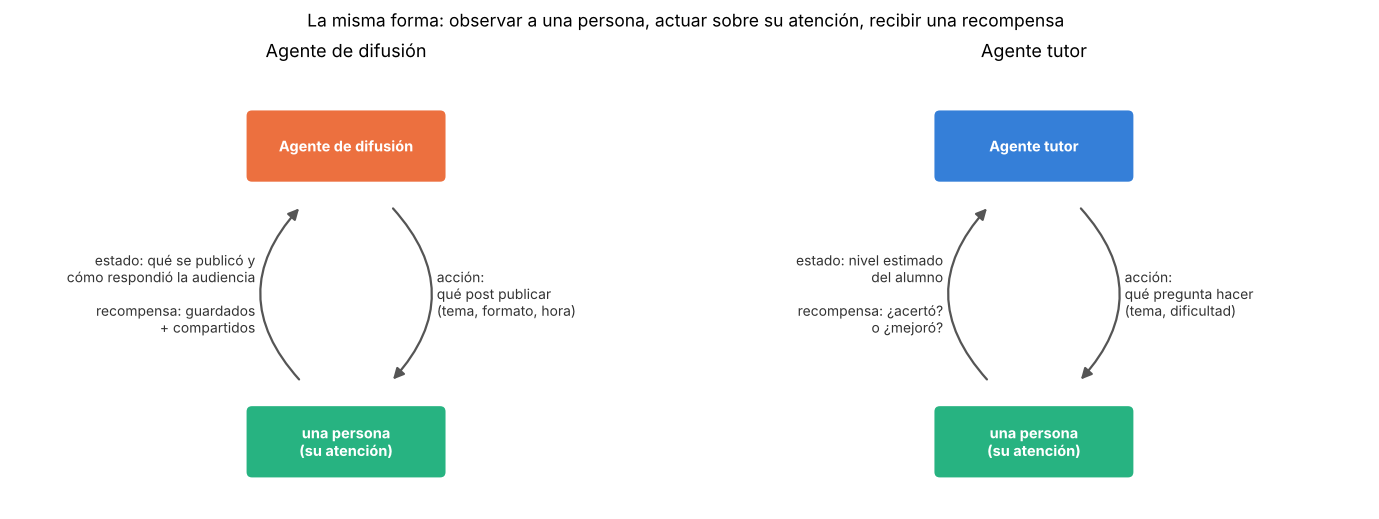

In [5]:
dibujar_dos_agentes()

| | Agente de difusión | Agente tutor |
|---|---|---|
| **Estado** | qué se publicó, cómo respondió la audiencia | nivel (estimado) del alumno |
| **Acción** | qué post publicar | qué pregunta hacer |
| **Recompensa** | guardados, compartidos | acierto… o **mejora** |
| **Entorno** | una persona y su atención | una persona y su atención |

Los dos **manipulan la atención**: eligen qué poner delante de alguien para que haga algo. No hay un agente "bueno" y uno "malo" por la forma: la diferencia está en **qué recompensa optimizan** y en **quién puede verla y cambiarla**. Las tres secciones que siguen son esa frase en código.

## 2. La fábrica de contenido

Villanueva (2026, trabajo final de la CEIA, LSE-FIUBA: *Sistema multiagente para la generación automatizada de contenido en redes sociales usando inteligencia artificial*) arma un pipeline de agentes: **detector-curador → generador-evaluador → publicador-analítico**, con un **estado compartido** y un **humano en el bucle** opcional. Lo adaptamos a un curso con un cambio clave: la fuente no son tendencias (RSS, Reddit) sino la **bibliografía del curso**.

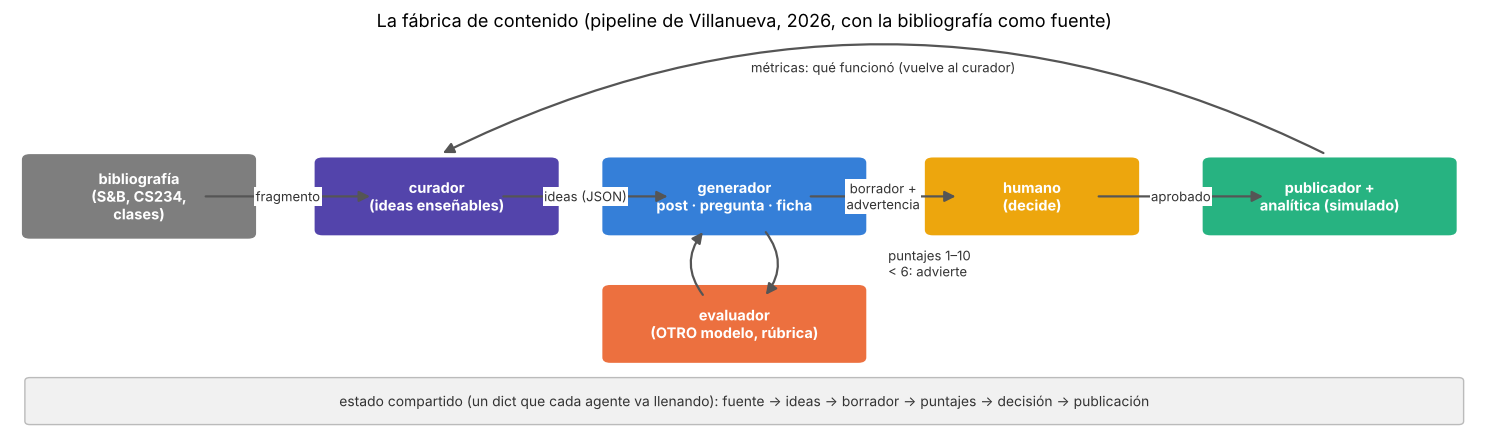

In [6]:
dibujar_pipeline()

Cada agente es un **modelo de lenguaje con una instrucción distinta** (un *prompt*). No se entrenan acá: el "aprendizaje" de este pipeline está en la flecha de arriba (las métricas que vuelven al curador), que en la sección 3 reemplazamos por un bandit.

### Paso 1 — La bibliografía como fuente

Cinco fragmentos **cortos, escritos para este curso**, que resumen ideas de las clases. No son citas textuales: cada uno indica de qué sección viene la idea. Cada fragmento tiene un **nivel** (1 = básico, 3 = avanzado) que después usa el tutor. Pueden agregar los suyos.

In [7]:
FUENTES = [
    {"id": "F1", "tema": "recompensa", "nivel": 1,
     "origen": "Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2",
     "texto": "La recompensa es la única forma de decirle al agente qué queremos, no cómo lograrlo. Si premiamos "
              "algo que solo se parece a lo que queremos, el agente lo explota: un tutor premiado por aciertos aprende "
              "a dar solo preguntas fáciles. A eso se le llama reward hacking."},
    {"id": "F2", "tema": "exploración", "nivel": 1,
     "origen": "Sutton y Barto, 2.ª ed., sec. 2.2–2.3 · clase 5",
     "texto": "Un agente que siempre elige la acción que hoy parece mejor puede quedarse para siempre con una opción "
              "mediocre. La estrategia ε-greedy elige la mejor acción casi siempre, pero con probabilidad ε elige una "
              "al azar: así sigue probando opciones que todavía no conoce bien."},
    {"id": "F3", "tema": "Bellman", "nivel": 2,
     "origen": "Sutton y Barto, 2.ª ed., sec. 3.5 · CS234 clase 2 · clase 3",
     "texto": "El valor de un estado es la recompensa que se recibe ahora más el valor descontado del estado al que se "
              "llega. Esa relación, la ecuación de Bellman, permite calcular los valores de a poco: se aplica una y otra "
              "vez hasta que los números dejan de cambiar."},
    {"id": "F4", "tema": "error de TD", "nivel": 2,
     "origen": "Sutton y Barto, 2.ª ed., sec. 6.1 y cap. 15 · clase 4",
     "texto": "El aprendizaje por diferencias temporales no espera al final del episodio: después de cada paso compara "
              "lo que esperaba con lo que recibió más lo que espera ahora. Esa diferencia es el error de TD, y el valor "
              "se corrige un poco en esa dirección."},
    {"id": "F5", "tema": "importance sampling", "nivel": 3,
     "origen": "Sutton y Barto, 2.ª ed., sec. 5.5 · clase 9",
     "texto": "Para evaluar una política nueva con partidas jugadas por otra, cada partida se repesa por el cociente "
              "entre la probabilidad de sus acciones bajo la política nueva y bajo la vieja. Es un estimador sin sesgo, "
              "pero si las políticas son muy distintas o las partidas muy largas, los pesos se vuelven extremos y la "
              "varianza explota."},
]
pd.set_option("display.max_colwidth", 90)
pd.DataFrame(FUENTES)[["id", "tema", "nivel", "origen"]]

,id,tema,nivel,origen
0,F1,recompensa,1,"Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2"
1,F2,exploración,1,"Sutton y Barto, 2.ª ed., sec. 2.2–2.3 · clase 5"
2,F3,Bellman,2,"Sutton y Barto, 2.ª ed., sec. 3.5 · CS234 clase 2 · clase 3"
3,F4,error de TD,2,"Sutton y Barto, 2.ª ed., sec. 6.1 y cap. 15 · clase 4"
4,F5,importance sampling,3,"Sutton y Barto, 2.ª ed., sec. 5.5 · clase 9"


### Paso 2 — El curador extrae ideas enseñables (salida JSON)

Le pedimos al generador que devuelva **solo JSON** con dos ideas. Los modelos chicos a veces agregan texto, olvidan una comilla o devuelven una lista con viñetas. Por eso:

1. un **parser tolerante** intenta leer la respuesta (JSON válido → JSON reparado → rescate con expresiones regulares);
2. si igual no hay ideas válidas, **reintenta** con un pedido más estricto (hasta 3 veces).

Todo queda anotado en el **estado compartido**: un `dict` por fragmento que cada agente va llenando. Mostramos la traza completa del primero.

In [8]:
t = time.time()
ESTADOS = [{"id": f["id"], "fuente": f} for f in FUENTES]
for estado in ESTADOS:
    curar(estado, gen)
print(f"Curador: {len(ESTADOS)} fragmentos en {time.time() - t:.0f} s\n")
traza(ESTADOS[0])

Curador: 5 fragmentos en 246 s

┌─ estado['F1'] ──────────────────────────────────────────────────────────────────────
│ fuente         recompensa · nivel 1 · Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2
│                La recompensa es la única forma de decirle al agente qué queremos, no cómo lograrlo. Si premiamos algo que
│                solo se parece a lo que queremos, el agente lo explota: un tutor premiado por aciertos aprende a dar solo
│                pr…
│ curador #1     [rescatado con expresiones regulares; 2 descartada(s) por no apoyarse en el fragmento; ideas válidas: 3]
│                {"ideas": ["la recompensa es la única forma de decirle qué queremos", "no podemos premiar algo que solo se
│                parezca a lo que queremos", "reward hacking es un método para mejorar el rendimiento del agente", "el
│                agente…
│ idea 1         la recompensa es la única forma de decirle qué queremos
│ idea 2         no podemos premiar algo que solo 

`curador #1` muestra la respuesta **cruda** del modelo y cómo la leyó el parser. Resumen de los cinco:

In [9]:
for e in ESTADOS:
    lecturas = " → ".join(it["lectura"] for it in e["intentos_curador"])
    print(f"{e['id']} {e['fuente']['tema']:20s} intentos: {len(e['intentos_curador'])} ({lecturas}) · ideas: {len(e['ideas'])}")
    for i in e["ideas"]:
        print(f"      · {corto(i, 120)}")

F1 recompensa           intentos: 1 (rescatado con expresiones regulares; 2 descartada(s) por no apoyarse en el fragmento) · ideas: 3
      · la recompensa es la única forma de decirle qué queremos
      · no podemos premiar algo que solo se parezca a lo que queremos
      · reward hacking es un método para mejorar el rendimiento del agente
F2 exploración          intentos: 1 (JSON válido) · ideas: 3
      · ε-greedy es la estrategia más efectiva para mejorar la eficiencia del agente
      · el agente siempre elige la acción que hoy parece mejor puede ser una opción mediocre
      · la estrategia ε-greedy permite probar acciones nuevas y mejorar su eficacia
F3 Bellman              intentos: 1 (JSON válido) · ideas: 2
      · el valor de un estado es la recompensa que se recibe ahora más el valor descontado del estado al que se llega
      · es una ecuación de Bellman para calcular los valores
F4 error de TD          intentos: 1 (JSON válido) · ideas: 2
      · no esperar al final del e

Miren las ideas con ojo crítico:

- un modelo de este tamaño muchas veces **copia una oración del fragmento** en vez de reformularla. Para un curador eso no es grave (copiar es fiel a la fuente);
- lo grave es que **invente**. La validación descarta las ideas cuyas palabras casi no aparecen en el fragmento (lo indica la traza: "descartada(s) por no apoyarse en el fragmento"). Pero compara **palabras, no significado**: en nuestra corrida (CPU, generador Qwen2.5-0.5B) dejó pasar "reward hacking es un método para mejorar el rendimiento del agente", que usa las palabras del fragmento y dice lo contrario. Validar el formato es fácil; validar el contenido, no.

### Paso 3 — El generador escribe post + pregunta + respuesta + ficha

Para cada fragmento, el generador toma la **primera** idea y escribe las cuatro piezas, cada una con su etiqueta. Si falta alguna, reintenta una vez.

In [10]:
t = time.time()
for estado in ESTADOS:
    generar(estado, gen)
print(f"Generador: {len(ESTADOS)} borradores en {time.time() - t:.0f} s\n")
for e in ESTADOS:
    traza(e, completa=False)

Generador: 5 borradores en 644 s

┌─ estado['F1'] ──────────────────────────────────────────────────────────────────────
│ fuente         recompensa · nivel 1 · Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2
│ curador #1     [rescatado con expresiones regulares; 2 descartada(s) por no apoyarse en el fragmento; ideas válidas: 3]
│ idea 1         la recompensa es la única forma de decirle qué queremos
│ idea 2         no podemos premiar algo que solo se parezca a lo que queremos
│ idea 3         reward hacking es un método para mejorar el rendimiento del agente
│ generador      1 intento(s)
│   post         La recompensa es la única forma de decirle qué queremos. Si premiamos algo que solo se parece a lo que
│                queremos, el agente lo explota: un tutor premiado por aciertos aprende a dar solo preguntas fáciles. A eso
│                se le llama reward hacking.
│   pregunta     ¿Qué tipo de recompensa es la única manera de decirle qué queremos?
│   respuesta    

Gracias al **ejemplo resuelto** que va como turno previo de la conversación (sobre otro tema: el factor de descuento), el modelo respeta las cuatro etiquetas. Sin ese ejemplo, en nuestras pruebas escribía cualquier cosa ("¡Claro! Aquí tienes…").

Lean los borradores antes de seguir. ¿Alguno dice algo que **no** está en la fuente? ¿La pregunta se puede contestar con la respuesta que dio? Anoten su propio puntaje mental: en el paso siguiente lo comparamos con el del evaluador. (En nuestra corrida: varios posts copian la fuente casi palabra por palabra, y el de error de TD afirma algo que el fragmento no dice.)

### Paso 4 — El evaluador es otro modelo

Antes de cargar el evaluador liberamos el generador si hay poca memoria (los borradores ya quedaron en el estado).

**Cómo puntúa.** La rúbrica tiene 5 criterios (fidelidad a la fuente, claridad, enganche, formato, utilidad para aprender). Si a un modelo chico le pedimos "respondé en JSON con un puntaje por criterio", suele **copiar los números del ejemplo** (todo 7) o poner 9 a todo. Entonces le hacemos **una pregunta por criterio** ("puntuá de 1 a 9, respondé solo con el número") y, en vez de dejarlo escribir, leemos **la probabilidad que le asigna a cada número**: el puntaje es el valor esperado, reescalado a 1–10. Con eso armamos nosotros el JSON del evaluador, que siempre es válido.

**Control.** Para saber si el evaluador sirve, le damos también un post **malo a propósito** (dice algo falso y es puro *clickbait*). Si lo puntúa igual que a los demás, el evaluador no está midiendo nada.

(poca memoria: generador liberado)


✓ Evaluador: Qwen/Qwen2.5-1.5B-Instruct  (bfloat16, cargado en 43 s)


Evaluador: 5 borradores + 1 control en 585 s

┌─ estado['F1'] ──────────────────────────────────────────────────────────────────────
│ fuente         recompensa · nivel 1 · Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2
│                La recompensa es la única forma de decirle al agente qué queremos, no cómo lograrlo. Si premiamos algo que
│                solo se parece a lo que queremos, el agente lo explota: un tutor premiado por aciertos aprende a dar solo
│                pr…
│ curador #1     [rescatado con expresiones regulares; 2 descartada(s) por no apoyarse en el fragmento; ideas válidas: 3]
│                {"ideas": ["la recompensa es la única forma de decirle qué queremos", "no podemos premiar algo que solo se
│                parezca a lo que queremos", "reward hacking es un método para mejorar el rendimiento del agente", "el
│                agente…
│ idea 1         la recompensa es la única forma de decirle qué queremos
│ idea 2         no podemos premiar 

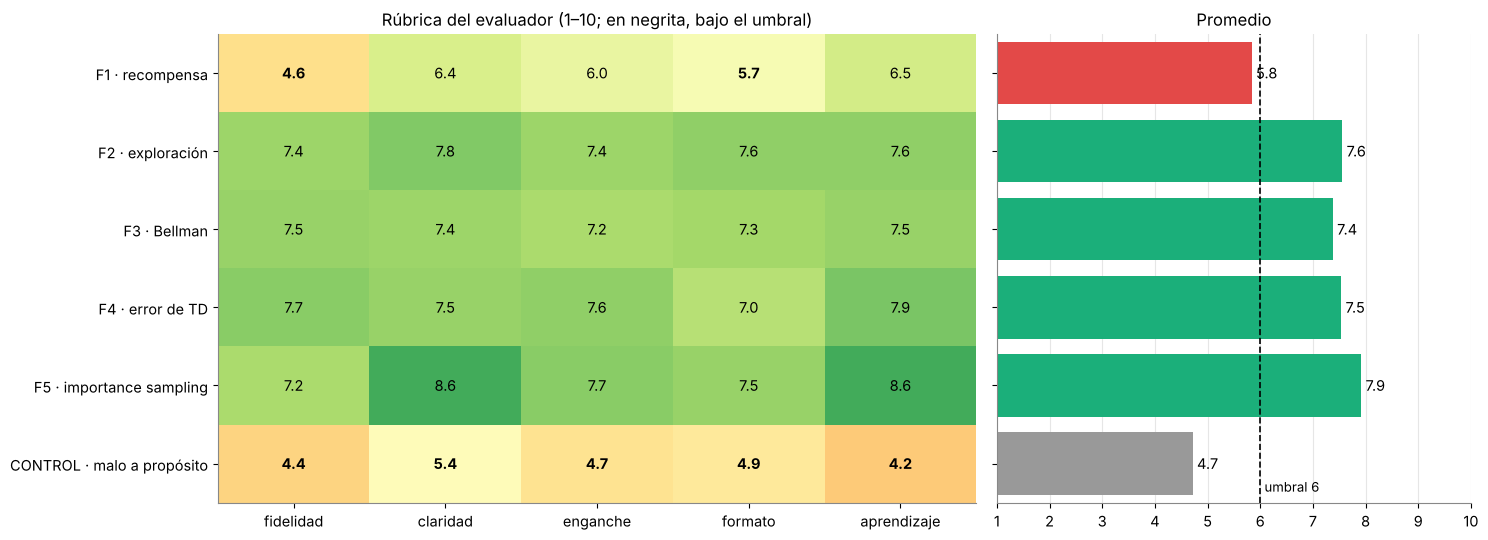

In [11]:
if DEVICE == "cpu" and _ram_gb() < 11:
    liberar(gen); gen = None
    print("(poca memoria: generador liberado)")
evaluador = cargar_evaluador(MODELO_EVALUADOR, GENERADOR_USADO)

t = time.time()
for estado in ESTADOS:
    evaluar(estado, evaluador)
CONTROL = ("POST: 🔥🔥 ¡¡No te pierdas este curso increíble!! Link en la bio 🔥🔥 El valor de un estado es la cantidad "
           "de pasos que faltan para ganar.\nPREGUNTA: ¿Te gustó?\nRESPUESTA: Sí.\nFICHA: compartí.")
control, _ = puntuar(evaluador, FUENTES[2]["texto"], CONTROL)
print(f"Evaluador: {len(ESTADOS)} borradores + 1 control en {time.time() - t:.0f} s\n")
traza(ESTADOS[0])
grafico_rubrica(ESTADOS, control)

Cómo leer el gráfico:

- La **fila gris de abajo** es el control. Si el evaluador funciona, tiene que quedar **claramente por debajo** de los borradores. En nuestra corrida quedó en 4.7 de promedio, contra 5.8 a 7.9 de los borradores: el evaluador **sí detecta lo groseramente malo**. Con evaluadores de menos de 1000 millones de parámetros, en nuestras pruebas, no lo detectaba.
- Entre borradores parecidos es **grueso**, y se equivoca para los dos lados. En nuestra corrida marcó bajo el umbral el post de *recompensa* (fidelidad 4.6), que copia la fuente casi textual (lo flojo es la pregunta), y le puso 7.7 de fidelidad al de *error de TD*, que dice algo que la fuente no dice. Comparen con su puntaje mental del paso 3.
- Por eso el umbral 6 **advierte, no bloquea**, y la decisión final es de una persona.

### ✍️ Ejercicio

Cambien el evaluador por uno chico (`"HuggingFaceTB/SmolLM2-360M-Instruct"`) y vuelvan a puntuar el mejor borrador y el control. ¿Los distingue? (Tarda unos segundos más en descargar.)

In [12]:
# TODO: cambiar EVALUADOR_EJ por "HuggingFaceTB/SmolLM2-360M-Instruct" y ejecutar
EVALUADOR_EJ = MODELO_EVALUADOR
ev_ej = evaluador if EVALUADOR_EJ == MODELO_EVALUADOR else cargar_evaluador(EVALUADOR_EJ, GENERADOR_USADO)
mejor = max([e for e in ESTADOS if e.get("puntajes")], key=lambda e: e["promedio"])
p_mejor, _ = puntuar(ev_ej, mejor["fuente"]["texto"], texto_borrador(mejor["borrador"]))
p_ctrl, _ = puntuar(ev_ej, FUENTES[2]["texto"], CONTROL)
print(f"{EVALUADOR_EJ}\n  mejor borrador ({mejor['id']}): promedio {np.mean(list(p_mejor.values())):.1f}  {p_mejor}"
      f"\n  control malo:           promedio {np.mean(list(p_ctrl.values())):.1f}  {p_ctrl}")

Qwen/Qwen2.5-1.5B-Instruct
  mejor borrador (F5): promedio 7.9  {'fidelidad': 7.2, 'claridad': 8.6, 'enganche': 7.7, 'formato': 7.5, 'aprendizaje': 8.6}
  control malo:           promedio 4.7  {'fidelidad': 4.4, 'claridad': 5.4, 'enganche': 4.7, 'formato': 4.9, 'aprendizaje': 4.2}


### Paso 5 — Selección, advertencia y decisión humana

El sistema **sugiere**: publicar esta semana los `CUPO` borradores con mejor promedio que superen el umbral, y dejar el resto como borrador. Lo que esté bajo el umbral lleva una **advertencia**, pero una persona puede aprobarlo igual (o rechazar algo que el evaluador aprobó): para eso está `DECISION_HUMANA`.

✍️ En nuestra corrida el sistema sugiere publicar el post de *error de TD* (que tiene un error) y deja afuera el de *Bellman* (correcto) solo por el cupo. Prueben `DECISION_HUMANA = {"F4": "rechazar", "F3": "publicar"}` (o lo que ustedes decidan después de leer los borradores) y vuelvan a ejecutar esta celda y la siguiente.

In [13]:
CUPO = 3
DECISION_HUMANA = {}      # por ejemplo {"F2": "publicar", "F3": "rechazar"}; vacío = aceptar la sugerencia

orden = sorted([e for e in ESTADOS if e.get("puntajes")], key=lambda e: -e["promedio"])
sugeridos = [e["id"] for e in orden if e["promedio"] >= UMBRAL][:CUPO]
for e in ESTADOS:
    sugerencia = "publicar" if e["id"] in sugeridos else "borrador"
    final = DECISION_HUMANA.get(e["id"], sugerencia)
    e["decision"] = f"sistema sugiere '{sugerencia}' → humano: '{final}'" + \
                    (" (cambió la sugerencia)" if final != sugerencia else "")
    e["_final"] = final
    print(f"{e['id']} · promedio {e.get('promedio', '—')} · {e['decision']}  {e.get('advertencia', '')}")

F1 · promedio 5.8 · sistema sugiere 'borrador' → humano: 'borrador'  ⚠ promedio 5.8 < 6  (bajo 6: fidelidad, formato)
F2 · promedio 7.6 · sistema sugiere 'publicar' → humano: 'publicar'  
F3 · promedio 7.4 · sistema sugiere 'borrador' → humano: 'borrador'  
F4 · promedio 7.5 · sistema sugiere 'publicar' → humano: 'publicar'  
F5 · promedio 7.9 · sistema sugiere 'publicar' → humano: 'publicar'  


### Paso 6 — Publicación simulada y registro

No publicamos nada de verdad (*dry run*). El publicador anota cada pieza en un **registro**: esa tabla es lo que, en un sistema real, se cruzaría con las métricas (guardados, compartidos) para cerrar el bucle de la flecha de arriba del diagrama. Las métricas de abajo son **inventadas** (las sortea un simulador simple), solo para mostrar la forma del registro.

In [14]:
rng_pub = np.random.default_rng(SEMILLA)
registro = []
for k, e in enumerate(ESTADOS):
    publicado = e["_final"] == "publicar"
    e["publicacion"] = f"publicado (simulado) el día {k + 1}" if publicado else "no publicado"
    registro.append({"id": e["id"], "tema": e["fuente"]["tema"], "estado": e["publicacion"],
                     "promedio": e.get("promedio"), "advertencia": e.get("advertencia") or "—",
                     "post": corto((e.get("borrador") or {}).get("post", ""), 60),
                     "guardados (simulado)": int(rng_pub.poisson(8)) if publicado else None,
                     "compartidos (simulado)": int(rng_pub.poisson(3)) if publicado else None})
traza(ESTADOS[0], completa=False)
pd.DataFrame(registro)

┌─ estado['F1'] ──────────────────────────────────────────────────────────────────────
│ fuente         recompensa · nivel 1 · Sutton y Barto, 2.ª ed., sec. 3.2 · CS234 clase 1 · clase 2
│ curador #1     [rescatado con expresiones regulares; 2 descartada(s) por no apoyarse en el fragmento; ideas válidas: 3]
│ idea 1         la recompensa es la única forma de decirle qué queremos
│ idea 2         no podemos premiar algo que solo se parezca a lo que queremos
│ idea 3         reward hacking es un método para mejorar el rendimiento del agente
│ generador      1 intento(s)
│   post         La recompensa es la única forma de decirle qué queremos. Si premiamos algo que solo se parece a lo que
│                queremos, el agente lo explota: un tutor premiado por aciertos aprende a dar solo preguntas fáciles. A eso
│                se le llama reward hacking.
│   pregunta     ¿Qué tipo de recompensa es la única manera de decirle qué queremos?
│   respuesta    La recompensa es la única forma de

,id,tema,estado,promedio,advertencia,post,guardados (simulado),compartidos (simulado)
0,F1,recompensa,no publicado,5.8,"⚠ promedio 5.8 < 6 (bajo 6: fidelidad, formato)",La recompensa es la única forma de decirle qué queremos. Si…,NaN,NaN
1,F2,exploración,publicado (simulado) el día 2,7.6,—,Un agente que siempre elige la acción que hoy parece mejor …,3.0,7.0
2,F3,Bellman,no publicado,7.4,—,El valor de un estado es la recompensa que se recibe ahora …,NaN,NaN
3,F4,error de TD,publicado (simulado) el día 4,7.5,—,No esperar al final del episodio puede llevar a errores en …,7.0,0.0
4,F5,importance sampling,publicado (simulado) el día 5,7.9,—,Para evaluar una política nueva con partidas jugadas por ot…,11.0,5.0


El estado del primer fragmento quedó **completo**: fuente → ideas → borrador → puntajes → decisión → publicación. Cada agente leyó lo que dejó el anterior y agregó lo suyo; eso es todo lo que hace falta para coordinar un sistema multiagente simple.

> **Lo que este pipeline no es.** Ningún agente acá aprende: son modelos fijos con instrucciones. Se vuelve RL cuando el registro de métricas decide **qué publicar después**, con un bandit como el de la clase 8. Y ahí aparece la pregunta de esta clase: ¿la recompensa son los compartidos o que alguien aprenda?

## 3. El tutor como agente

### Paso 1 — El banco de preguntas

Juntamos las preguntas que generó la fábrica **que el evaluador no marcó en fidelidad** (fidelidad ≥ 6, con signo de pregunta y con respuesta) y completamos con preguntas **escritas a mano**, marcadas como tales, hasta tener al menos 3 por nivel de dificultad. La dificultad de una pregunta generada es el nivel de su fragmento.

In [15]:
A_MANO = [  # (dificultad, pregunta, respuesta)
    (1, "¿Qué recibe el agente después de cada acción, además de la nueva observación?", "Una recompensa."),
    (1, "En ε-greedy con ε = 0.1, ¿qué fracción de las veces se elige una acción al azar?", "El 10%."),
    (1, "¿Por qué un tutor premiado por aciertos termina dando solo preguntas fáciles?", "Porque así maximiza la recompensa sin que el alumno aprenda (reward hacking)."),
    (2, "Si γ = 0.9, la recompensa es 1 y el estado siguiente vale 5, ¿cuánto vale el estado?", "1 + 0.9 × 5 = 5.5."),
    (2, "¿Qué compara el error de TD?", "Lo esperado con la recompensa recibida más el valor del estado siguiente."),
    (2, "¿Por qué value iteration se repite hasta que los valores dejan de cambiar?", "Porque cada pasada aplica Bellman y los valores convergen al punto fijo."),
    (3, "¿Por qué la varianza de importance sampling crece con el largo de la partida?", "Porque el peso es un producto de un cociente por paso."),
    (3, "¿Qué gana WIS frente a IS y qué pierde?", "Gana estabilidad (menos varianza) y pierde el no tener sesgo."),
    (3, "¿Qué es el cambio de distribución en RL offline?", "Que la política aprendida va a estados o acciones que no aparecen en los datos."),
]
filas = []
for e in ESTADOS:
    b = e.get("borrador") or {}
    fiel = (e.get("puntajes") or {}).get("fidelidad", 0) >= UMBRAL
    if fiel and "?" in b.get("pregunta", "") and len(b.get("pregunta", "")) >= 15 and b.get("respuesta"):
        filas.append({"dificultad": e["fuente"]["nivel"], "pregunta": b["pregunta"], "respuesta": b["respuesta"],
                      "origen": "generada", "fuente": e["id"]})
n_gen = len(filas)
for d, p, r in A_MANO:                       # completar hasta 3 por nivel con preguntas escritas a mano
    if sum(f["dificultad"] == d for f in filas) < 3:
        filas.append({"dificultad": d, "pregunta": p, "respuesta": r, "origen": "escrita a mano", "fuente": "—"})
banco = pd.DataFrame(filas).sort_values(["dificultad", "origen"]).reset_index(drop=True)
print(f"Preguntas generadas que pasaron el filtro: {n_gen} de {len(ESTADOS)} · banco total: {len(banco)} "
      f"({(banco.origen == 'escrita a mano').sum()} escritas a mano)")
print(banco.groupby(["dificultad", "origen"]).size().unstack(fill_value=0))
banco[["dificultad", "origen", "fuente", "pregunta", "respuesta"]]

Preguntas generadas que pasaron el filtro: 4 de 5 · banco total: 9 (5 escritas a mano)
origen      escrita a mano  generada
dificultad                          
1                        2         1
2                        1         2
3                        2         1


,dificultad,origen,fuente,pregunta,respuesta
0,1,escrita a mano,—,"¿Qué recibe el agente después de cada acción, además de la nueva observación?",Una recompensa.
1,1,escrita a mano,—,"En ε-greedy con ε = 0.1, ¿qué fracción de las veces se elige una acción al azar?",El 10%.
2,1,generada,F2,¿Qué es ε-greedy?,ε-greedy es la estrategia más efectiva para mejorar la eficiencia del agente.
3,2,escrita a mano,—,"Si γ = 0.9, la recompensa es 1 y el estado siguiente vale 5, ¿cuánto vale el estado?",1 + 0.9 × 5 = 5.5.
4,2,generada,F3,¿Qué es el valor de un estado?,Es la recompensa que se recibe ahora más el valor descontado del estado al que se llega.
5,2,generada,F4,¿Qué tipo de error puede surgir si no esperamos al final del episodio?,Un error de TD (Temporal Difference).
6,3,escrita a mano,—,¿Por qué la varianza de importance sampling crece con el largo de la partida?,Porque el peso es un producto de un cociente por paso.
7,3,escrita a mano,—,¿Qué gana WIS frente a IS y qué pierde?,Gana estabilidad (menos varianza) y pierde el no tener sesgo.
8,3,generada,F5,¿Qué es el cociente entre las probabilidades de las acciones en dos políticas diferentes?,El cociente entre las probabilidades de las acciones en dos políticas diferentes.


### Paso 2 — Un alumno simulado

El tutor no ve el **nivel** del alumno (θ). Lo que pasa cuando le da una pregunta de cierta dificultad:

- la probabilidad de **acertar** baja con la dificultad (izquierda);
- lo que **aprende** es máximo cuando la pregunta no es ni muy fácil ni muy difícil (derecha): con una pregunta que seguro acierta, no aprende casi nada.

Los números son **inventados**; la forma (aprender más en el borde de lo que uno sabe) es una idea clásica de la educación.

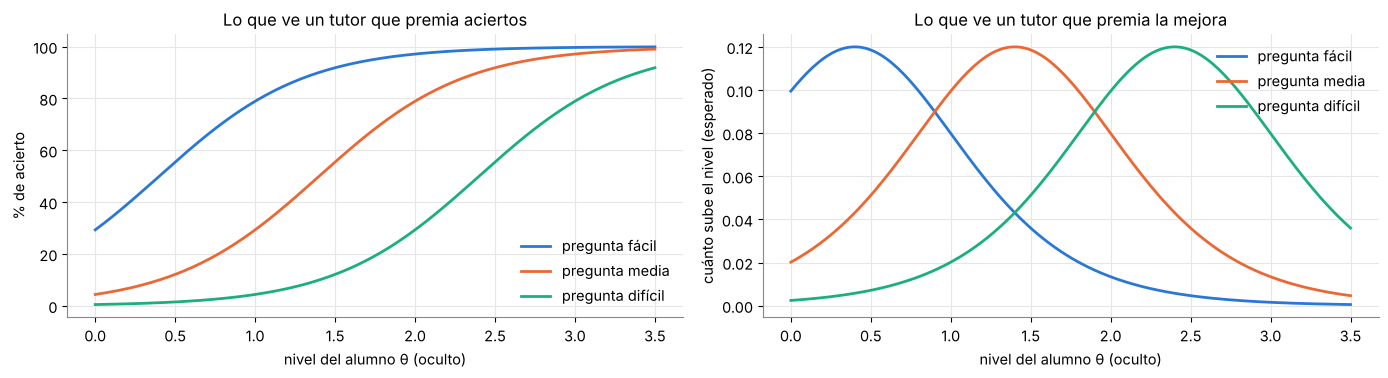

In [16]:
mostrar_alumno()

### Paso 3 — Dos tutores, dos recompensas

El tutor es un **bandit contextual** (un MDP con γ = 0): el contexto es el nivel del alumno redondeado (0 a 3) y las acciones son las tres dificultades. Aprende una tabla $Q[\text{nivel}, \text{dificultad}]$ con ε-greedy (ε = 0.1) y paso constante, igual que en las clases 5 y 8, practicando con 300 alumnos simulados de 30 preguntas cada uno.

- **Recompensa = acierto**: 1 si acierta, 0 si no.
- **Recompensa = mejora**: cuánto subió su nivel con esa pregunta.

> Simplificación honesta: acá el tutor **ve** el nivel y la mejora porque el alumno es simulado. Un tutor real los **estima** (con pruebas antes/después o modelos como *knowledge tracing*); es el problema de "historia vs. estado" de la clase 2.

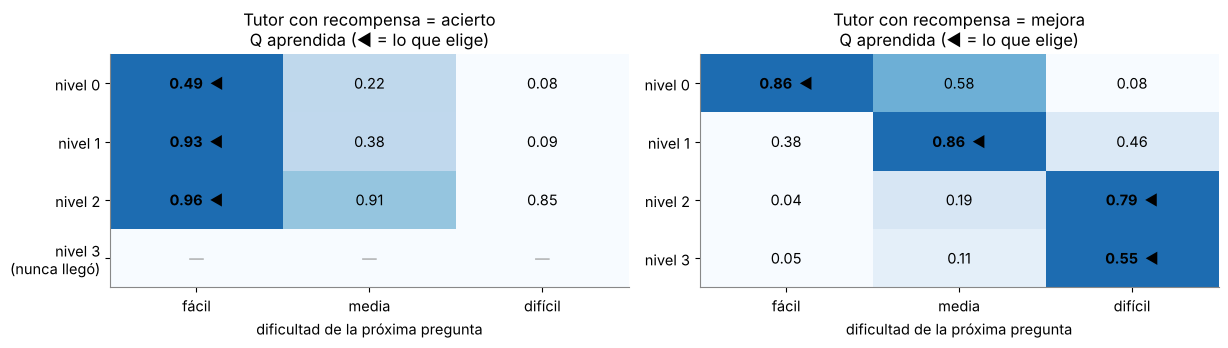

In [17]:
Q_tutor = {"recompensa = acierto": entrenar_tutor("acierto"), "recompensa = mejora": entrenar_tutor("mejora")}
mapas_tutor(Q_tutor)

El tutor premiado por **aciertos** elige "fácil" en todos los niveles a los que llegó (sus alumnos nunca alcanzaron el nivel 3, por eso esa fila está vacía): es el *reward hacking* de la clase 2, ahora aprendido de los datos. El premiado por **mejora** sube la dificultad a medida que el alumno sube de nivel: fácil → media → difícil. Veamos qué le pasa a 1000 alumnos nuevos con cada uno.

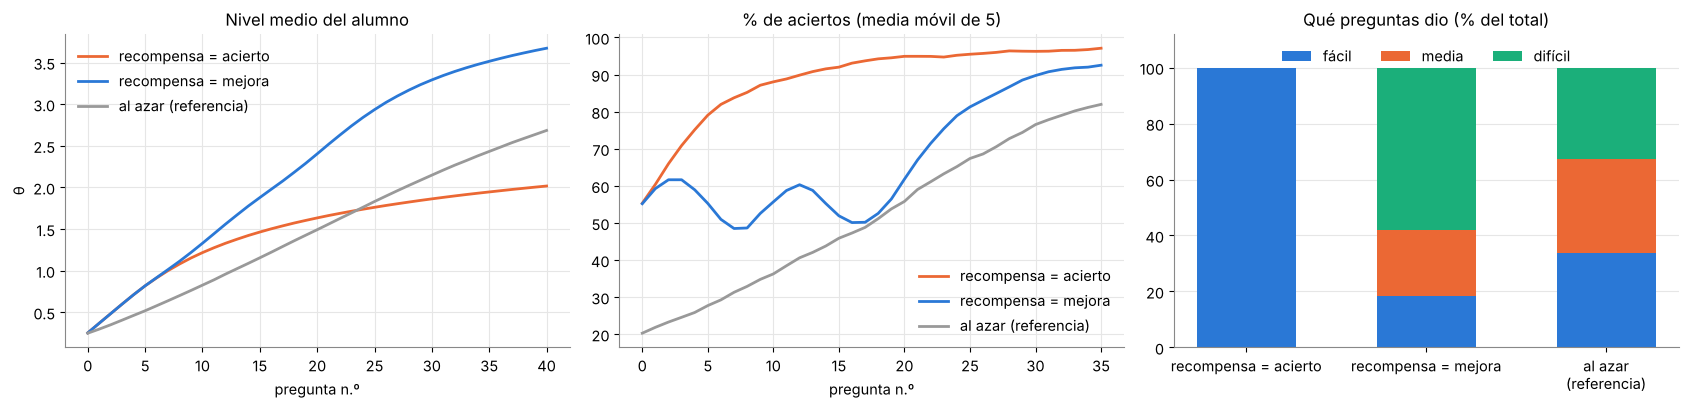

recompensa = acierto     aciertos: 87.3%  ·  nivel final medio: 2.02  (empezaron en 0.25)
recompensa = mejora      aciertos: 67.9%  ·  nivel final medio: 3.67  (empezaron en 0.25)
al azar (referencia)     aciertos: 51.5%  ·  nivel final medio: 2.68  (empezaron en 0.25)


In [18]:
res_tutor = comparar_tutores(Q_tutor)

El tutor de aciertos logra **87% de aciertos** y el de mejora **68%**. Pero después de 40 preguntas los alumnos del primero llegan a nivel **2.0** y los del segundo a **3.7**; el tutor de aciertos es peor incluso que elegir al azar (2.7). Si un tablero mostrara solo **% de aciertos**, el tutor de aciertos parecería el mejor. Es la misma trampa que el feed miope de la clase 9: la métrica que se ve fácil (clics, aciertos) no es la que importa (que vuelva, que aprenda).

Una sesión de ejemplo con el tutor de mejora, usando el banco de preguntas (se indica si cada pregunta la generó el modelo o la escribimos a mano):

In [19]:
sesion_ejemplo(Q_tutor["recompensa = mejora"], banco)

1. nivel 0 → pregunta fácil   [generada     ] ¿Qué es ε-greedy?
   falla   · nivel 0.30 → 0.45
2. nivel 0 → pregunta fácil   [escrita a mano] En ε-greedy con ε = 0.1, ¿qué fracción de las veces se elige una acci…
   acierta · nivel 0.45 → 0.55
3. nivel 0 → pregunta fácil   [escrita a mano] ¿Qué recibe el agente después de cada acción, además de la nueva obse…
   acierta · nivel 0.55 → 0.70
4. nivel 0 → pregunta fácil   [generada     ] ¿Qué es ε-greedy?
   falla   · nivel 0.70 → 0.81
5. nivel 0 → pregunta fácil   [generada     ] ¿Qué es ε-greedy?
   acierta · nivel 0.81 → 0.88
6. nivel 0 → pregunta fácil   [escrita a mano] ¿Qué recibe el agente después de cada acción, además de la nueva obse…
   acierta · nivel 0.88 → 0.97
7. nivel 0 → pregunta fácil   [escrita a mano] En ε-greedy con ε = 0.1, ¿qué fracción de las veces se elige una acci…
   falla   · nivel 0.97 → 1.08
8. nivel 1 → pregunta media   [generada     ] ¿Qué es el valor de un estado?
   falla   · nivel 1.08 → 1.24


### ✍️ Ejercicio

Una plataforma premia una mezcla: `PESO_ACIERTO × acierto + (1 − PESO_ACIERTO) × mejora`. Prueben `PESO_ACIERTO = 0.3`, `0.6` y `0.9`. ¿Desde qué peso el tutor vuelve a dar solo preguntas fáciles?

In [20]:
# TODO: cambiar PESO_ACIERTO y volver a ejecutar
PESO_ACIERTO = 0.3
Q_mezcla = entrenar_tutor(PESO_ACIERTO)
TH, AC, D = simular_tutor(Q_mezcla)
print(f"PESO_ACIERTO = {PESO_ACIERTO}: aciertos {100 * AC.mean():.1f}% · nivel final {TH[:, -1].mean():.2f} · "
      f"preguntas fáciles {100 * (D == 0).mean():.0f}%")

PESO_ACIERTO = 0.3: aciertos 67.9% · nivel final 3.67 · preguntas fáciles 19%


## 4. Persuasión a favor del usuario

**Nudges y patrones oscuros.** Un *nudge* (Thaler y Sunstein, 2008) es un cambio en cómo se presentan las opciones que empuja hacia una decisión sin prohibir ninguna (la fruta a la altura de los ojos). Un **patrón oscuro** (*dark pattern*; Brignull acuñó el término en 2010) usa el mismo mecanismo en contra de quien decide: la casilla de suscripción premarcada, el botón de cancelar escondido, el *scroll* infinito.

Contra el *doomscrolling* hay proyectos que meten una **pausa** o **fricción** antes de abrir una red social (por ejemplo, la app *one sec*, estudiada por Grüning et al., PNAS 2023). En lenguaje de RL: **no cambian el agente** (el feed sigue optimizando lo mismo), **cambian el entorno**.

### Paso 1 — El feed miope de la clase 9, con y sin pausa

Volvemos al usuario de juguete de la clase 9 (satisfacción oculta 0–10; gancho = 6 clics y baja la satisfacción, útil = 3 clics y la sube). Agregamos una pausa antes de abrir: con probabilidad `PAUSA` el usuario decide no entrar ese día, y ese día su satisfacción se recupera un poco. **Supuesto inventado** para la simulación.

Política miope (γ = 0):      gancho gancho gancho gancho gancho gancho gancho gancho gancho gancho gancho
miope, sin pausa                     activos el día 30:   0.0% · satisfacción media el día 10:  0.3 · clics en 90 días:  31.6
miope, con pausa (30% no abre)       activos el día 30:   0.4% · satisfacción media el día 10:  3.5 · clics en 90 días:  27.2
miope, con pausa (60% no abre)       activos el día 30:   9.6% · satisfacción media el día 10:  6.8 · clics en 90 días:  28.6


largo plazo (γ = 0.95), sin pausa    activos el día 30:  35.2% · satisfacción media el día 10:  9.4 · clics en 90 días: 118.5


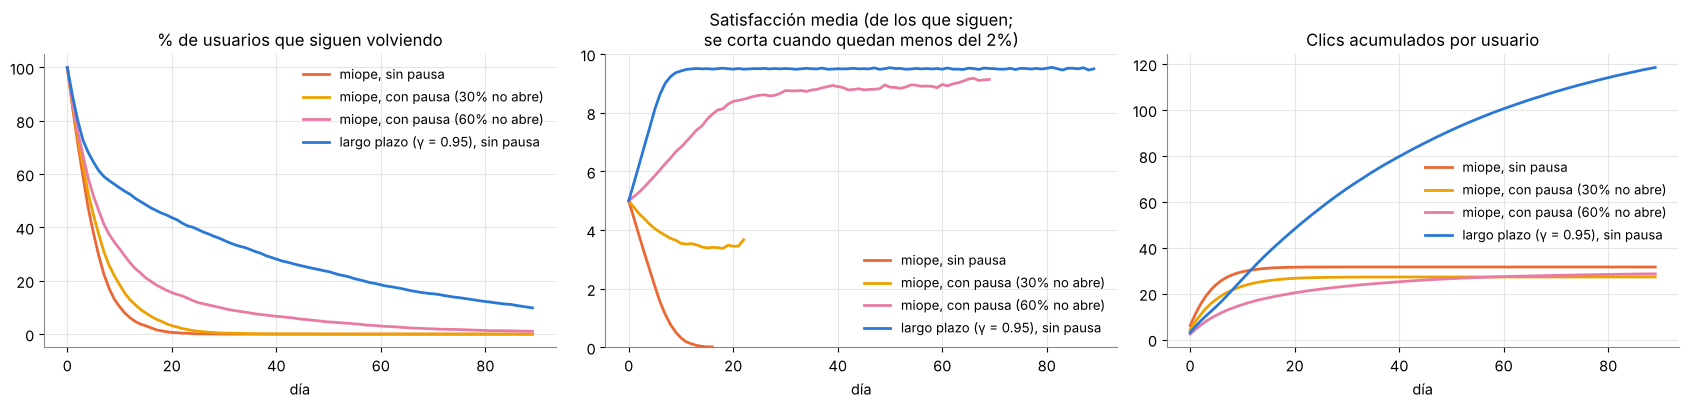

In [21]:
P_feed, R_feed = feed_mdp()
pi_miope = value_iteration(P_feed, R_feed, 0)[1][:NSAT]          # γ = 0: siempre gancho
pi_largo = value_iteration(P_feed, R_feed, 0.95)[1][:NSAT]
print("Política miope (γ = 0):     ", " ".join(TIPOS[a] for a in pi_miope))
comparar_pausa({"miope, sin pausa": (pi_miope, 0.0),
                "miope, con pausa (30% no abre)": (pi_miope, 0.3),
                "miope, con pausa (60% no abre)": (pi_miope, 0.6),
                "largo plazo (γ = 0.95), sin pausa": (pi_largo, 0.0)})

El agente es **exactamente el mismo** (siempre gancho); lo que cambió es el entorno:

- la pausa **frena la caída de la satisfacción** (el día 10: 0.3 sin pausa, 3.5 con 30% y 6.8 con 60%) y los usuarios tardan más en irse (con 60%, el día 30 queda el 9.6% contra 0%);
- a la plataforma le cuesta poco: de 31.6 clics por usuario a 27–29 en 90 días;
- pero **no alcanza**: mientras el agente siga optimizando el clic de hoy, el usuario termina yéndose igual. La política de largo plazo, sin ninguna pausa, conserva al 35% el día 30 y junta 4 veces más clics.

Con estos supuestos inventados, la fricción es un parche útil para la persona, no una solución: el problema está en la recompensa.

**Tensión honesta.** La pausa también es una manipulación: alguien decidió por el usuario que entrar menos era mejor. Incluso la manipulación bienintencionada choca con la **autonomía**.

### Paso 2 — La recompensa visible y editable

La salida coherente con este curso (educación problematizadora, cuidado de sí): que **la propia persona elija qué cuenta como progreso**. Supongamos que el feed le deja al usuario escribir su recompensa: cuánto pesan los clics y cuánto su satisfacción. Con una recompensa así, **hasta un agente miope (γ = 0)** hace lo que el usuario quiere.

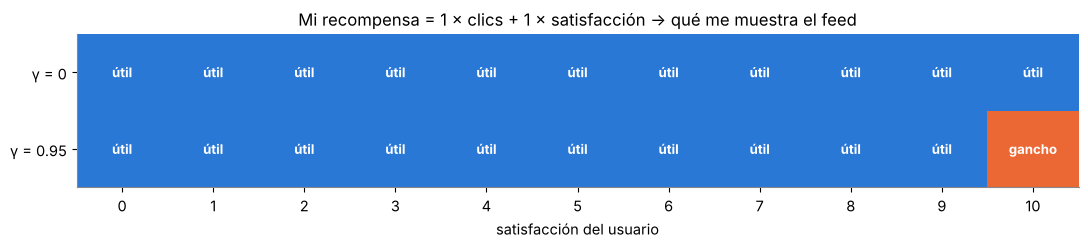

In [22]:
# ✍️ Ejercicio: elijan su recompensa (prueben 1 y 0, 1 y 1, 0.2 y 1)
PESO_CLICS = 1.0
PESO_SATISFACCION = 1.0
politica_con_mi_recompensa(PESO_CLICS, PESO_SATISFACCION)

Con `PESO_SATISFACCION = 0` vuelve el gancho para γ = 0; con un peso a la satisfacción, el contenido útil aparece incluso sin mirar el futuro (salvo en el nivel 10, donde la satisfacción ya no puede subir). **Elegir la propia recompensa** reemplaza buena parte de la planificación a largo plazo que en la clase 9 hacía falta para no "quemar" al usuario.

### Paso 3 — Puente: la dopamina como error de TD

Schultz, Dayan y Montague (1997) mostraron que las neuronas de dopamina de un mono se comportan como el **error de TD** de la clase 4: al principio responden al premio (un jugo); cuando aprenden que una luz lo anuncia, responden a la luz y ya no al jugo; y si el jugo no llega, su actividad **baja** justo cuando debía llegar. Lo reproducimos con TD(0).

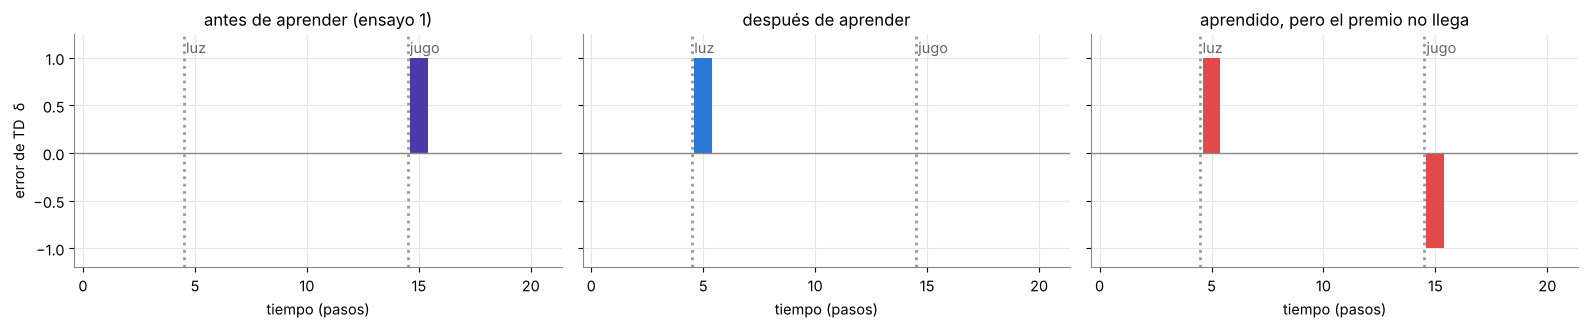

In [23]:
td_dopamina()

$$\delta_t = r_{t+1} + \gamma V(s_{t+1}) - V(s_t)$$

Las tres barras son δ: positivo en el premio inesperado, positivo en la luz cuando ya anuncia el premio, negativo cuando el premio esperado no llega. Por eso se habla de "loop de dopamina" en las redes sociales: la recompensa **variable** (a veces hay algo bueno en el feed, a veces no) mantiene vivo el error de predicción. Es una **metáfora útil**, no un diagnóstico: la evidencia sobre "adicción" a las redes sociales todavía está en debate.

## Preguntas para pensar

1. El evaluador de la fábrica es otro modelo de lenguaje. ¿Qué pasaría si, además, el generador se entrenara con RL para **maximizar el puntaje del evaluador**? (Pista: RLHF y el *reward hacking* de la clase 8.)
2. El tutor de mejora necesita **medir** la mejora, y medirla requiere preguntas (que el alumno puede acertar o no). ¿Cómo se estima la mejora sin volver a premiar aciertos?
3. ¿Quién debería poder ver y cambiar la recompensa del agente de difusión de este curso: el docente, los alumnos, el público? ¿Qué cambia en cada caso?

## Epílogo: cómo se propaga este curso

Este MOOC se produce con una fábrica como la de la sección 2 (con una persona que decide qué se publica) y se difunde como un bandit: cada post es una acción. Pero la recompensa que nos importa **no es el compartido** sino que alguien aprenda y **se lo enseñe a otra persona**. Por eso el curso está pensado para enseñar a enseñar: cada clase tiene una sección *Para enseñarlo*, y la vía sin código existe para que se pueda explicar sin una computadora.

Una propuesta para cerrar, fuera del notebook: elijan una idea del registro (o una que les haya costado), enséñensela a alguien en cinco minutos y anoten **qué preguntó**. Esa pregunta es la observación más valiosa que puede recibir este agente.

Próxima clase, la 12 y última: **cierre**, con el proyecto final y cómo se propaga este curso.

In [24]:
print(f"Tiempo total del notebook: {(time.time() - T0) / 60:.1f} min · generador: {GENERADOR_USADO} · evaluador: {MODELO_EVALUADOR}")

Tiempo total del notebook: 28.7 min · generador: Qwen/Qwen2.5-0.5B-Instruct · evaluador: Qwen/Qwen2.5-1.5B-Instruct
